# Evaluación del modelo toy


### 1. Definir toy model simple

In [1]:
import cobra


def modelo_toy_simple():
    """
    Modelo toy con tres especies metabólicamente complementarias.

    B1: auxótrofo de glutamato, consume glucosa.
    B2: especialista en acetato.
    B3: especialista en succinato.

    Cada especie tiene una fuente de carbono preferente
    y se restringe el consumo de las fuentes asignadas
    a las otras especies.
    """

    base = cobra.io.load_model("textbook")

    B1 = base.copy()
    B2 = base.copy()
    B3 = base.copy()

    # --------------------------------------------------
    # B1: consumidor de glucosa, auxótrofo de glutamato
    # --------------------------------------------------

    B1.reactions.get_by_id("GLUDy").bounds = (0, 0)
    B1.reactions.get_by_id("GLUSy").bounds = (0, 0)

    # Evitar consumo de acetato y succinato
    B1.reactions.get_by_id("ACt2r").bounds = (0, 0)
    B1.reactions.get_by_id("SUCCt2_2").bounds = (0, 0)

    # --------------------------------------------------
    # B2: especialista en acetato
    # --------------------------------------------------

    B2.reactions.get_by_id("GLCpts").bounds = (0, 0)
    B2.reactions.get_by_id("SUCCt2_2").bounds = (0, 0)

    # --------------------------------------------------
    # B3: especialista en succinato
    # --------------------------------------------------

    B3.reactions.get_by_id("GLCpts").bounds = (0, 0)
    B3.reactions.get_by_id("ACt2r").bounds = (0, 0)

    modelos = {
        "B1": B1,
        "B2": B2,
        "B3": B3
    }

    return modelos


# Medio de cultivo común
medio = {
    "glc__D_e": (-10, 100),
    "ac_e": (-10, 100),
    "succ_e": (-10, 100),
    "o2_e": (-15, 100),
    "glu__L_e": (-10, 100),
    "nh4_e": (-100, 100),
    "pi_e": (-100, 100),
    "h2o_e": (-100, 100),
    "h_e": (-100, 100),
    "co2_e": (-100, 100)
}

medios_individuales = {
    "B1": medio.copy(),
    "B2": medio.copy(),
    "B3": medio.copy()
}

### 2. Implementar metodo

In [2]:
# Importaciones necesarias
import importlib
import metodo.community_moma as cm
importlib.reload(cm)
import metodo.results as results
importlib.reload(results)
from metodo.referencias import calcular_referencias, imprimir_referencias
import numpy as np
import pandas as pd

In [3]:
# Evaluar referencias
modelos = modelo_toy_simple()
referencias = calcular_referencias(modelos, medio, medios_individuales)
imprimir_referencias(referencias)

Set parameter Username
Set parameter LicenseID to value 2854514
Academic license - for non-commercial use only - expires 2027-08-19
Read LP format model from file /var/folders/s0/4ql9zp392d588l6dcrm3xn900000gn/T/tmp5m41idke.lp
Reading time = 0.00 seconds
: 72 rows, 190 columns, 720 nonzeros
Read LP format model from file /var/folders/s0/4ql9zp392d588l6dcrm3xn900000gn/T/tmpsbbs78oj.lp
Reading time = 0.00 seconds
: 72 rows, 190 columns, 720 nonzeros
Read LP format model from file /var/folders/s0/4ql9zp392d588l6dcrm3xn900000gn/T/tmpz_jqdoif.lp
Reading time = 0.00 seconds
: 72 rows, 190 columns, 720 nonzeros
Read LP format model from file /var/folders/s0/4ql9zp392d588l6dcrm3xn900000gn/T/tmp3jg1_i6r.lp
Reading time = 0.00 seconds
: 72 rows, 190 columns, 720 nonzeros
Read LP format model from file /var/folders/s0/4ql9zp392d588l6dcrm3xn900000gn/T/tmpr7rrbl02.lp
Reading time = 0.00 seconds
: 72 rows, 190 columns, 720 nonzeros
Read LP format model from file /var/folders/s0/4ql9zp392d588l6dcrm3x

In [4]:
# Barrido de crecimiento (Community MOMA) para diferentes valores de alpha
alphas = np.linspace(0.5, 1.0, 11)

resultados = cm.barrido_moma(
    referencias=referencias,
    medio=medio,
    alphas=alphas,
    residentes=["B1", "B2"],
    invasores=["B3"],
    pesos="norma",
    coexistencia=True
)

Read LP format model from file /var/folders/s0/4ql9zp392d588l6dcrm3xn900000gn/T/tmp1txfeezy.lp
Reading time = 0.00 seconds
: 72 rows, 190 columns, 720 nonzeros
Read LP format model from file /var/folders/s0/4ql9zp392d588l6dcrm3xn900000gn/T/tmp9vd2demr.lp
Reading time = 0.00 seconds
: 72 rows, 190 columns, 720 nonzeros
Set parameter NonConvex to value 2
Set parameter OptimalityTarget to value 1
Set parameter TimeLimit to value 600
mu=0.424946 | status=18 | soluciones=1 | objetivo=1.220663
alpha=0.50 | mu=0.424946 | status=18 | 
mu=0.467440 | status=18 | soluciones=1 | objetivo=0.988737
alpha=0.55 | mu=0.467440 | status=18 | 
mu=0.509935 | status=7 | soluciones=2 | objetivo=0.781388
alpha=0.60 | mu=0.509935 | status=7 | 
mu=0.552430 | status=7 | soluciones=2 | objetivo=0.598281
alpha=0.65 | mu=0.552430 | status=7 | 
mu=0.594924 | status=7 | soluciones=2 | objetivo=0.439593
alpha=0.70 | mu=0.594924 | status=7 | 
mu=0.637419 | status=7 | soluciones=2 | objetivo=0.305318
alpha=0.75 | mu=0.6

### 3. Resultados


In [9]:
results.imprimir_resumen(resultados)

COMPARACIÓN STEADYCOM vs COMMUNITY MOMA
Mu máximo SteadyCom reportado : 0.849892
Mu techo con coexistencia     : 0.849892

Abundancias de referencia SteadyCom:
  B1: 0.499757
  B2: 0.048061
  B3: 0.452182

Abundancias de referencia de residentes:
  B1: 0.499757
  B2: 0.500243

Resumen de resoluciones:
  Resoluciones ejecutadas : 11
  Soluciones factibles    : 11
  Sin solución factible   : 0

Mayor mu MOMA factible en el barrido: 0.849892
Alpha correspondiente              : 1.000000
Costo total correspondiente         : 0.007714
Estado de optimización               : 7


,alpha,mu,status,factible,objetivo,cost_residentes,cost_invasores,cost_total,tiempo,B1_MOMA,B1_Referencia,B2_MOMA,B2_Referencia,B3_MOMA,B3_Referencia
0,0.50,0.424946,18,True,1.220663,1.220663,7.774250e-14,1.220663,None,0.389485,0.499757,0.610515,0.500243,1.326419e-11,0.452182
1,0.55,0.467440,18,True,0.988737,0.988737,3.119904e-12,0.988737,None,0.409534,0.499757,0.590466,0.500243,5.420449e-11,0.452182
2,0.60,0.509935,7,True,0.781388,0.781380,8.089141e-06,0.781388,None,0.426318,0.499757,0.573682,0.500243,1.179809e-07,0.452182
3,0.65,0.552430,7,True,0.598281,0.598279,1.969562e-06,0.598281,None,0.440442,0.499757,0.559558,0.500243,1.762005e-08,0.452182
4,0.70,0.594924,7,True,0.439593,0.439592,5.519663e-07,0.439593,None,0.452553,0.499757,0.547447,0.500243,3.356149e-08,0.452182
5,0.75,0.637419,7,True,0.305318,0.305318,2.739612e-07,0.305318,None,0.463054,0.499757,0.536946,0.500243,1.925422e-08,0.452182
6,0.80,0.679913,18,True,0.195305,0.195305,-2.102311e-14,0.195305,None,0.472189,0.499757,0.527811,0.500243,0.000000e+00,0.452182
7,0.85,0.722408,18,True,0.109859,0.109859,-6.236765e-15,0.109859,None,0.480297,0.499757,0.519703,0.500243,0.000000e+00,0.452182
8,0.90,0.764902,7,True,0.048970,0.048970,9.527595e-08,0.048970,None,0.487606,0.499757,0.512394,0.500243,8.707814e-09,0.452182
9,0.95,0.807397,18,True,0.012206,0.012206,-2.735008e-14,0.012206,None,0.493953,0.499757,0.506047,0.500243,0.000000e+00,0.452182


(<Figure size 1000x500 with 1 Axes>,
 <Axes: title={'center': 'Abundancias: MOMA vs SteadyCom residentes (B1+B2)'}, xlabel='Tasa de crecimiento comunitario ($\\mu$)', ylabel='Abundancia relativa'>)

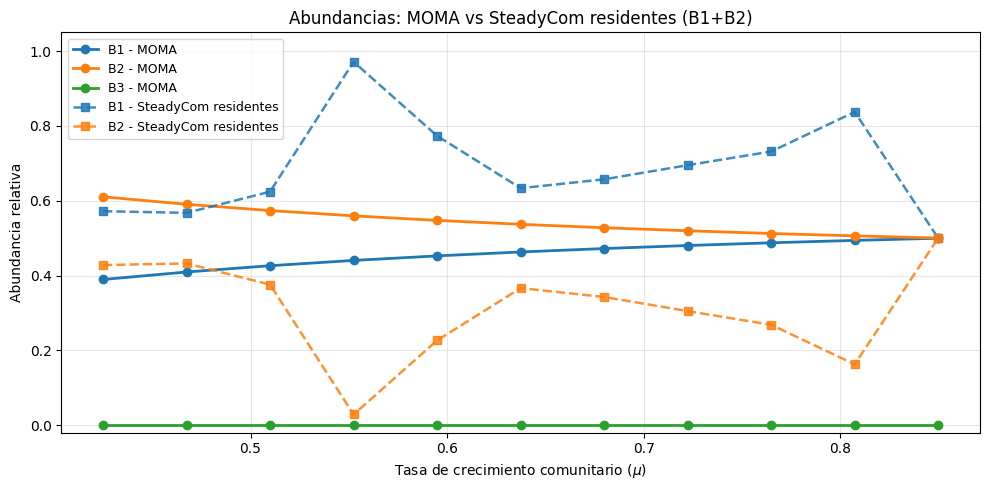

In [6]:
results.graficar_abundancias(resultados, medio)

(<Figure size 900x500 with 1 Axes>,
 <Axes: title={'center': 'Costo metabólico vs. crecimiento comunitario'}, xlabel='Tasa de crecimiento comunitario ($\\mu$)', ylabel='Costo metabólico (función objetivo)'>)

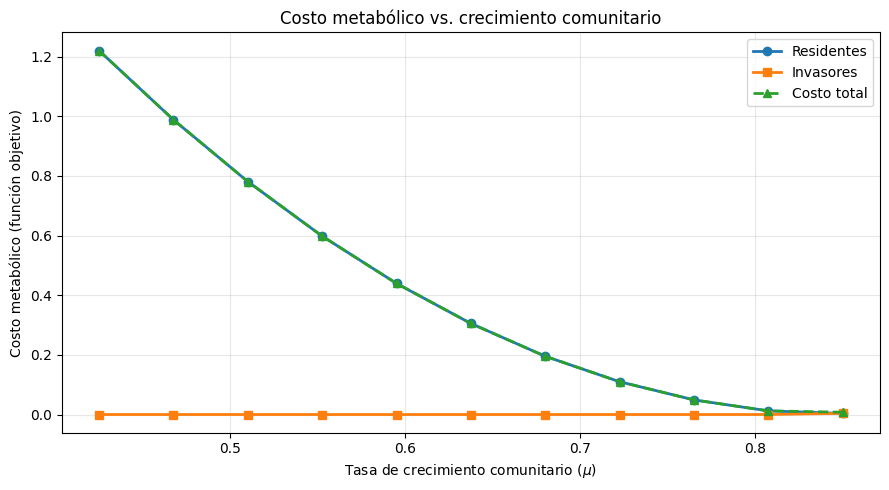

In [7]:
results.graficar_costo_metabolico(resultados)

Set parameter NonConvex to value 2
Set parameter OptimalityTarget to value 1
Set parameter TimeLimit to value 600
mu=0.424946 | status=18 | soluciones=1 | objetivo=0.061503
alpha=0.50 | mu=0.424946 | status=18 | 
mu=0.467440 | status=18 | soluciones=1 | objetivo=0.001292
alpha=0.55 | mu=0.467440 | status=18 | 
mu=0.509935 | status=18 | soluciones=1 | objetivo=0.824562
alpha=0.60 | mu=0.509935 | status=18 | 
mu=0.552430 | status=18 | soluciones=1 | objetivo=0.541152
alpha=0.65 | mu=0.552430 | status=18 | 
mu=0.594924 | status=18 | soluciones=1 | objetivo=0.317202
alpha=0.70 | mu=0.594924 | status=18 | 
mu=0.637419 | status=18 | soluciones=1 | objetivo=0.152712
alpha=0.75 | mu=0.637419 | status=18 | 
mu=0.679913 | status=18 | soluciones=1 | objetivo=0.047681
alpha=0.80 | mu=0.679913 | status=18 | 
mu=0.722408 | status=18 | soluciones=2 | objetivo=0.002110
alpha=0.85 | mu=0.722408 | status=18 | 
mu=0.764902 | status=7 | soluciones=2 | objetivo=12.000018
alpha=0.90 | mu=0.764902 | status=7

(<Figure size 900x500 with 1 Axes>,
 <Axes: title={'center': 'Costo metabólico vs. crecimiento comunitario'}, xlabel='Tasa de crecimiento comunitario ($\\mu$)', ylabel='Costo metabólico (función objetivo)'>)

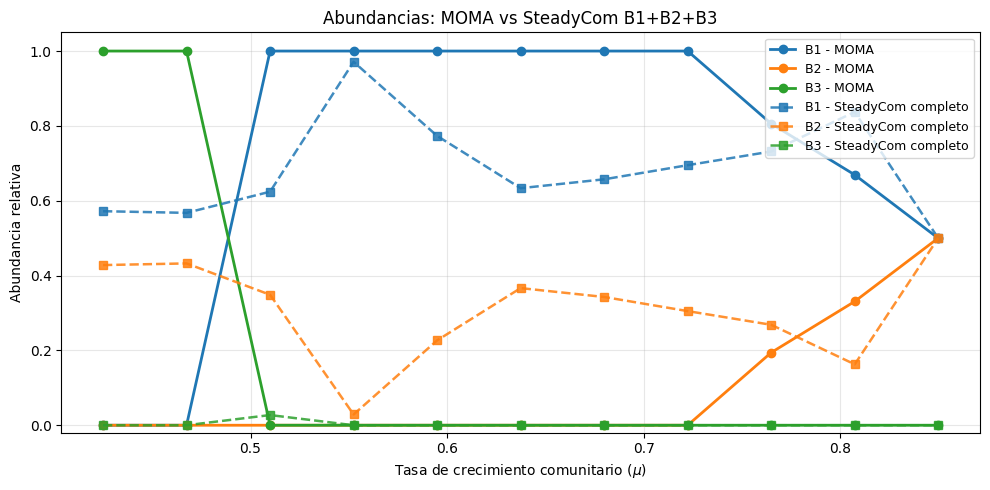

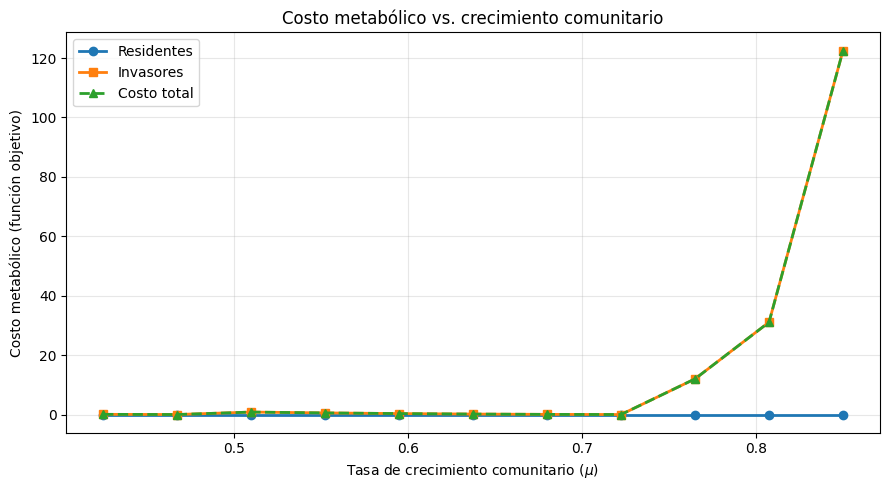

In [8]:
# Caso sin residentes, 3 invasores
resultados_sin_residentes = cm.barrido_moma(
    referencias=referencias,
    medio=medio,
    alphas=np.linspace(0.5, 1.0, 11),
    residentes=[],
    invasores=["B1", "B2", "B3"],
    coexistencia=True
)

results.graficar_abundancias(resultados_sin_residentes, medio)
results.graficar_costo_metabolico(resultados_sin_residentes)